# Univariate Elastic Net Regression — From Scratch

Uses L1 + L2 regularization without scikit-learn.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

X = np.arange(1, 51, dtype=float)
y = 2 * X + 1 + np.random.normal(0, 3, size=len(X))

train_size = int(0.8 * len(X))
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 40
Testing samples: 10


In [2]:
# Hyperparameters
learning_rate = 0.0005
lambda_l1 = 0.1
lambda_l2 = 0.1
epochs = 5000


In [3]:
def elastic_net(X, y, learning_rate, lambda_l1, lambda_l2, epochs):
    """Train univariate Elastic Net regression using gradient descent."""
    w = 0.0
    b = 0.0
    n = len(X)

    for epoch in range(epochs):
        # Prediction and error
        y_pred = w * X + b
        error = y_pred - y

        # Mean gradients of the MSE/2 term
        dw = np.mean(error * X)
        db = np.mean(error)
        
        dw += lambda_l1 * np.sign(w)
        dw += lambda_l2 * w

        # Parameter update
        w -= learning_rate * dw
        b -= learning_rate * db

        # Stop if numerical instability occurs
        if not (np.isfinite(w) and np.isfinite(b)):
            raise ValueError(
                "Training became unstable. Reduce learning_rate."
            )

    return w, b


w, b = elastic_net(
    X_train,
    y_train,
    learning_rate,
    lambda_l1,
    lambda_l2,
    epochs
)

print("Weight:", w)
print("Bias:", b)

Weight: 1.968450314162882
Bias: 0.783791853970826


In [4]:
# Prediction function
def predict(X):
    return w * X + b

y_train_pred = predict(X_train)
y_test_pred = predict(X_test)

# MSE
train_mse = np.mean((y_train - y_train_pred) ** 2)
test_mse = np.mean((y_test - y_test_pred) ** 2)

# Elastic Net objective: MSE/2 + L1 + L2
regularization = (
    lambda_l1 * abs(w)
    + (lambda_l2 / 2) * w**2
)

train_cost = train_mse / 2 + regularization
test_cost = test_mse / 2 + regularization

print("Training MSE:", train_mse)
print("Testing MSE:", test_mse)
print("Training Elastic Net Cost:", train_cost)
print("Testing Elastic Net Cost:", test_cost)

Training MSE: 7.626980035825636
Testing MSE: 7.2324338794556
Training Elastic Net Cost: 4.2040748812955036
Testing Elastic Net Cost: 4.006801803110486


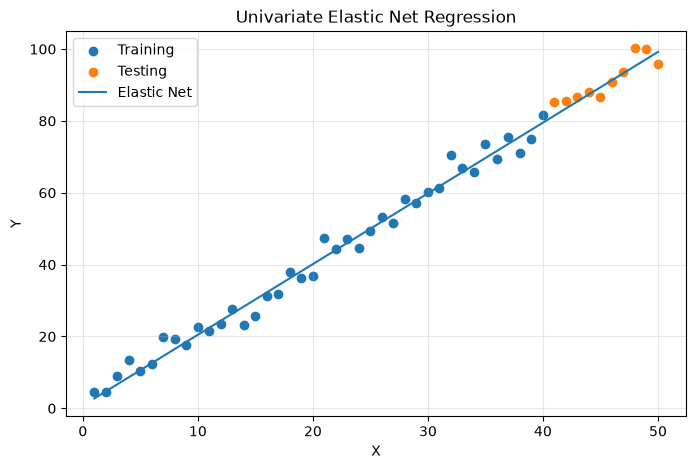

In [5]:
# Visualization
plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, label="Training")
plt.scatter(X_test, y_test, label="Testing")
plt.plot(X, predict(X), label="Elastic Net")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Univariate Elastic Net Regression")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()